In [1]:
import sys
print(sys.version)
import tensorflow as tf
print("TensorFlow:", tf.__version__)

3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]
TensorFlow: 2.21.0


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [3]:
# ---------- Setup cell: reload data and clean text (Tasks 1-2) ----------
import re
import pandas as pd

df = pd.read_csv("toxic_comments_dataset.csv")   # CSV must be in the notebook's folder

# Handle missing values and fully identical duplicate rows
df = df.dropna(subset=["Comment_Text", "Toxicity_Label"])
df = df.drop_duplicates().reset_index(drop=True)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)             # HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # URLs
    text = re.sub(r"[^\x00-\x7F]+", " ", text)     # emojis / non-ASCII
    text = re.sub(r"\d+", " ", text)               # numbers
    text = re.sub(r"[^a-z\s]", " ", text)          # punctuation / special chars
    text = re.sub(r"\s+", " ", text).strip()       # extra whitespace
    return text

df["Clean_Comment"] = df["Comment_Text"].apply(clean_text)
print("Shape:", df.shape)
df[["Comment_Text", "Clean_Comment"]].head()

Shape: (30000, 16)


,Comment_Text,Clean_Comment
0,The message targets a group unfairly and viola...,the message targets a group unfairly and viola...
1,Thank you for sharing this perspective with th...,thank you for sharing this perspective with th...
2,That response is aggressive and not helpful.,that response is aggressive and not helpful
3,I appreciate your explanation and the discussi...,i appreciate your explanation and the discussi...
4,I respectfully disagree but I understand your ...,i respectfully disagree but i understand your ...


Classes: ['Clean', 'Identity_Attack', 'Severe_Toxic', 'Threat', 'Toxic']
Training samples: 24000
Testing samples : 6000
Vocabulary size (incl. padding index 0): 88
Sample of word index: {'<OOV>': 1, 'and': 2, 'this': 3, 'i': 4, 'the': 5, 'your': 6, 'is': 7, 'helpful': 8, 'community': 9, 'message': 10}
Original text  : this message contains severe abusive language and should be removed
As sequence    : [3, 10, 51, 54, 55, 48, 2, 46, 47, 56]
Mean length       : 8.36
Max length        : 11
95th percentile   : 10.0
99th percentile   : 11.0


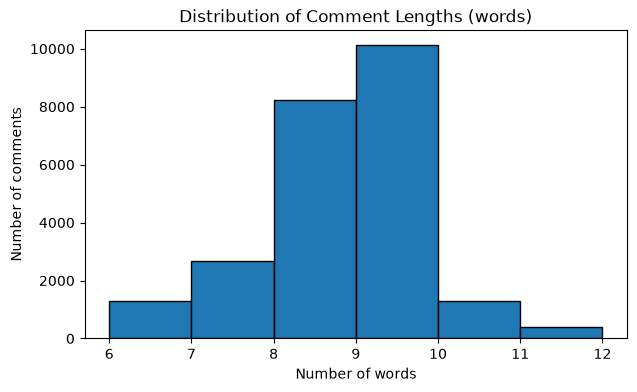

Selected MAX_LEN: 11
X_train_pad shape: (24000, 11)
X_test_pad shape : (6000, 11)
First padded sequence: [ 3 10 51 54 55 48  2 46 47 56  0]


In [6]:
le = LabelEncoder()
df["Label_Encoded"] = le.fit_transform(df["Toxicity_Label"])
print("Classes:", list(le.classes_))

X_train, X_test, y_train, y_test = train_test_split(
    df["Clean_Comment"], df["Label_Encoded"],
    test_size=0.2, random_state=42, stratify=df["Label_Encoded"])

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

MAX_WORDS = 5000            
OOV_TOKEN = "<OOV>"         

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(X_train)          

vocab_size = len(tokenizer.word_index) + 1
print("Vocabulary size (incl. padding index 0):", vocab_size)
print("Sample of word index:", dict(list(tokenizer.word_index.items())[:10]))

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq  = tokenizer.texts_to_sequences(X_test)

print("Original text  :", X_train.iloc[0])
print("As sequence    :", X_train_seq[0])

seq_lengths = [len(s) for s in X_train_seq]
print("Mean length       :", np.mean(seq_lengths).round(2))
print("Max length        :", np.max(seq_lengths))
print("95th percentile   :", np.percentile(seq_lengths, 95))
print("99th percentile   :", np.percentile(seq_lengths, 99))

plt.figure(figsize=(7, 4))
plt.hist(seq_lengths, bins=range(min(seq_lengths), max(seq_lengths) + 2), edgecolor="black")
plt.title("Distribution of Comment Lengths (words)")
plt.xlabel("Number of words")
plt.ylabel("Number of comments")
plt.show()

MAX_LEN = int(np.percentile(seq_lengths, 99))  
print("Selected MAX_LEN:", MAX_LEN)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post")
X_test_pad  = pad_sequences(X_test_seq,  maxlen=MAX_LEN, padding="post", truncating="post")

print("X_train_pad shape:", X_train_pad.shape)
print("X_test_pad shape :", X_test_pad.shape)
print("First padded sequence:", X_train_pad[0])

In [7]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense

tf.random.set_seed(42)
np.random.seed(42)

num_classes = len(le.classes_)                
input_dim   = min(MAX_WORDS, vocab_size)     
EMBED_DIM   = 64

y_train_arr = np.array(y_train)
y_test_arr  = np.array(y_test)

print("Number of classes:", num_classes)
print("Embedding input_dim:", input_dim)

model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=input_dim, output_dim=EMBED_DIM),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

model.summary()

EPOCHS     = 15
BATCH_SIZE = 64

history = model.fit(
    X_train_pad, y_train_arr,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,       
    verbose=1)

print("Final training accuracy  :", round(history.history["accuracy"][-1], 4))
print("Final validation accuracy:", round(history.history["val_accuracy"][-1], 4))
print("Final training loss      :", round(history.history["loss"][-1], 4))
print("Final validation loss    :", round(history.history["val_loss"][-1], 4))

Number of classes: 5
Embedding input_dim: 88


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 11, 64)              │           5,632 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             165 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 40,901 (159.77 KB)

 Trainable params: 40,901 (159.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.9028 - loss: 0.2406 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9989 - loss: 0.0058 - val_accuracy: 1.0000 - val_loss: 1.7223e-05
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9997 - loss: 0.0019 - val_accuracy: 1.0000 - val_loss: 2.2641e-06
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9998 - loss: 0.0018 - val_accuracy: 1.0000 - val_loss: 8.6133e-07
Epoch 5/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9997 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 1.9178e-07
Epoch 6/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9998 - loss: 8.6365e-04 - val_accuracy: 1.0000 - val_loss: 1.0250e-07
Epoch 7/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9998 - loss: 8.8811e-04 - val_accuracy: 1.0000 - val_loss: 3.9215e-08
Epoch 8/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9

Confusion Matrix:
 [[3716    0    0    0    0]
 [   0  293    0    0    0]
 [   0    0  360    0    0]
 [   0    0    0  292    0]
 [   0    0    0    0 1339]]


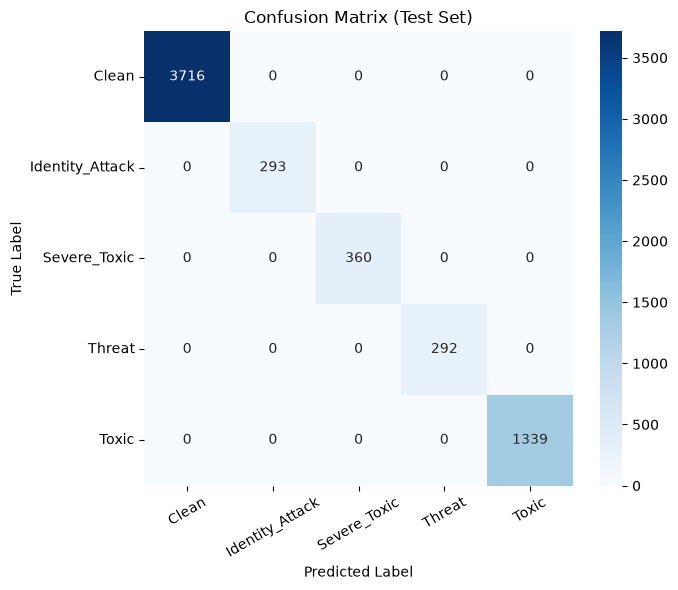

Test Loss    : 0.0000
Test Accuracy: 1.0000 (100.00%)
Classification Report:

                 precision    recall  f1-score   support

          Clean     1.0000    1.0000    1.0000      3716
Identity_Attack     1.0000    1.0000    1.0000       293
   Severe_Toxic     1.0000    1.0000    1.0000       360
         Threat     1.0000    1.0000    1.0000       292
          Toxic     1.0000    1.0000    1.0000      1339

       accuracy                         1.0000      6000
      macro avg     1.0000    1.0000    1.0000      6000
   weighted avg     1.0000    1.0000    1.0000      6000



In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

y_test_arr = np.array(y_test)

y_pred_prob = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test_arr, y_pred)
print("Confusion Matrix:\n", cm)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix (Test Set)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

test_loss, test_acc = model.evaluate(X_test_pad, y_test_arr, verbose=0)
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f} ({test_acc:.2%})")

print("Classification Report:\n")
print(classification_report(y_test_arr, y_pred, target_names=le.classes_, digits=4))